# Práctica IA con Inspiración Biológica
Master en Ciencia y Tecnología de la Carlos III de Madrid

Andrea López Salazar - 100475780

## 1. Preprocesamiento y tratamiento previo de datos
### 1.1. Carga y comprobación de los datasets

In [2]:
import numpy as np 
import pandas as pd

# semillas y rutas de los datasets
SEED    = 13
RUTAS   = {
    "diabetes"      : ("DATASETS/Diabetes.csv", "target"), 
    "california"    : ("DATASETS/California.csv", "MedHouseVal")
}

In [3]:
datos   = {}

for nombre, (ruta, objetivo) in RUTAS.items(): 
    df              = pd.read_csv(ruta)
    datos[nombre]   = (df.drop(columns=objetivo), df[objetivo])
    print(nombre, df.shape)

diabetes (442, 11)
california (20640, 9)


In [4]:
for nombre, (X,y) in datos.items(): 
    print(nombre)
    print("     nulos: ", X.isna().sum().sum() + y.isna().sum())
    print("     duplicados: ", pd.concat([X,y], axis=1).duplicated().sum())
    print("     tipos: ", set(X.dtypes.astype(str)))

diabetes
     nulos:  0
     duplicados:  0
     tipos:  {'float64'}
california
     nulos:  0
     duplicados:  0
     tipos:  {'float64'}


Los dos datasets que tenemos están aparentemente limpios, sin elementos nulos o duplicados. Todos los atributos, además, son de tipo float64, por lo que no tendremos que hacer transformaciones o tratamiento especial de categóricos.

### 1.2. Estadísticos descriptivos
Lo que queremos es ver la escala y el rango de cada uan de las variables, para comprobar si hay valores extraños. 

In [5]:
import matplotlib.pyplot as plt 

for nombre, (X,y) in datos.items(): 
    print(nombre)
    print(pd.concat([X,y], axis=1).describe().T.round(3))
    print()

diabetes
        count     mean     std     min     25%      50%      75%      max
age     442.0   -0.000   0.048  -0.107  -0.037    0.005    0.038    0.111
sex     442.0    0.000   0.048  -0.045  -0.045   -0.045    0.051    0.051
bmi     442.0   -0.000   0.048  -0.090  -0.034   -0.007    0.031    0.171
bp      442.0   -0.000   0.048  -0.112  -0.037   -0.006    0.036    0.132
s1      442.0   -0.000   0.048  -0.127  -0.034   -0.004    0.028    0.154
s2      442.0    0.000   0.048  -0.116  -0.030   -0.004    0.030    0.199
s3      442.0   -0.000   0.048  -0.102  -0.035   -0.007    0.029    0.181
s4      442.0   -0.000   0.048  -0.076  -0.039   -0.003    0.034    0.185
s5      442.0    0.000   0.048  -0.126  -0.033   -0.002    0.032    0.134
s6      442.0    0.000   0.048  -0.138  -0.033   -0.001    0.028    0.136
target  442.0  152.133  77.093  25.000  87.000  140.500  211.500  346.000

california
               count      mean       std      min      25%       50%  \
MedInc       20640.

#### Diabetes
- Los 10 atributos tienen media 0 y desviación de 0.048, todos idénticos. Esto puede indicar que ya han sido centrados y escalados previamente. No hace falta, por ende, normalizarlos. 
- La varibale `sex` realmente es una variable categórica codificada. 
- `target` va de 25 a 346, tiene media de 152 y mediana de 140,5. Esto nos indica que puede haber una ligera cola hacia la derecha (valores altos). Es la escala en la que se mide el MAE.

#### California
- Escalas muy distintas en las variables. 
- Valores extremos que están muy lejos del resto (se puede ver con el percentil 75%). 
- Las variables `HouseAge` y `MedHouseVal` acaban en 52 y 5,0. Esto puede sugerir un posible tope. 
- La latitud y longitud son coordenadas, y tratarlas como atributos numéricos normales puede darnos problemas.

#### Conclusiones principales tras el análisis
El dataset de diabetes está listo para modelar, pero el de California necesita escalado y decidir qué hacer con sus colas. Los MAE de los dos datasets no se podrían comparar entre sí, porque la `y` está en escalas distintas.

### 1.3. Confirmar y ver las distribuciones

In [6]:
print("Valores distintos de sex: ", datos["diabetes"][0]["sex"].nunique())

Valores distintos de sex:  2


Esto confirma que la variable `sex` del dataset de California es una variable binaria. 

In [ ]:
Xc, yc = datos["california"]
print("casas con HouseAge == 52:", (Xc["HouseAge"] == 52).sum())
print("casas con MedHouseVal == 5.0:", (yc == 5.0).sum())

casas con HouseAge == 52: 1273
casas con MedHouseVal == 5.0: 27


In [10]:
print(yc.max())
print((yc >= 5).sum())
print(yc.value_counts().head())

5.00001
992
MedHouseVal
5.00001    965
1.37500    122
1.62500    117
1.12500    103
1.87500     93
Name: count, dtype: int64


Como podemos ver, la variable objetivo - valor de la casa - está censurado y todas valen 5 (aprox). El valor real es desconocido. Un  modelo no puede distinguir estas casas entre sí, y por eso pone un límite al MAE que se puede alcanzar. 

#### Histogramas de Diabetes

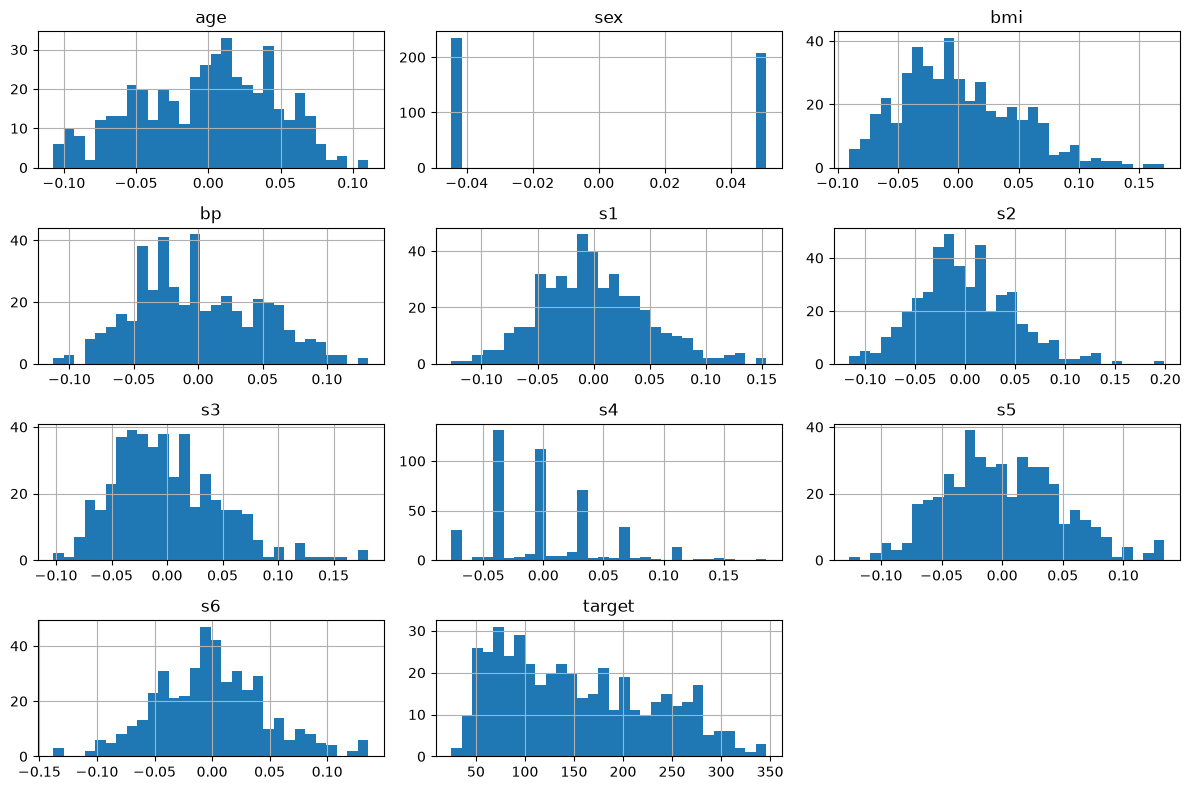

In [8]:
Xd, yd = datos["diabetes"]
pd.concat([Xd, yd], axis=1).hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

- se confirma que la variable `sex` es binaria. 

- `s4` tiene varios picos aislados. Parece que toma pocos valores distintos, acumulandose muchas filas en los mismos. 

- `bmi`, `s2`, `s3` presentan una cola ligera hacia la derecha, mientras el resto de atributos parecen simétricos aproximadamente.

- `target` tiene muchos más valores bajos, con cola hacia la derecha. 

#### Histogramas de California

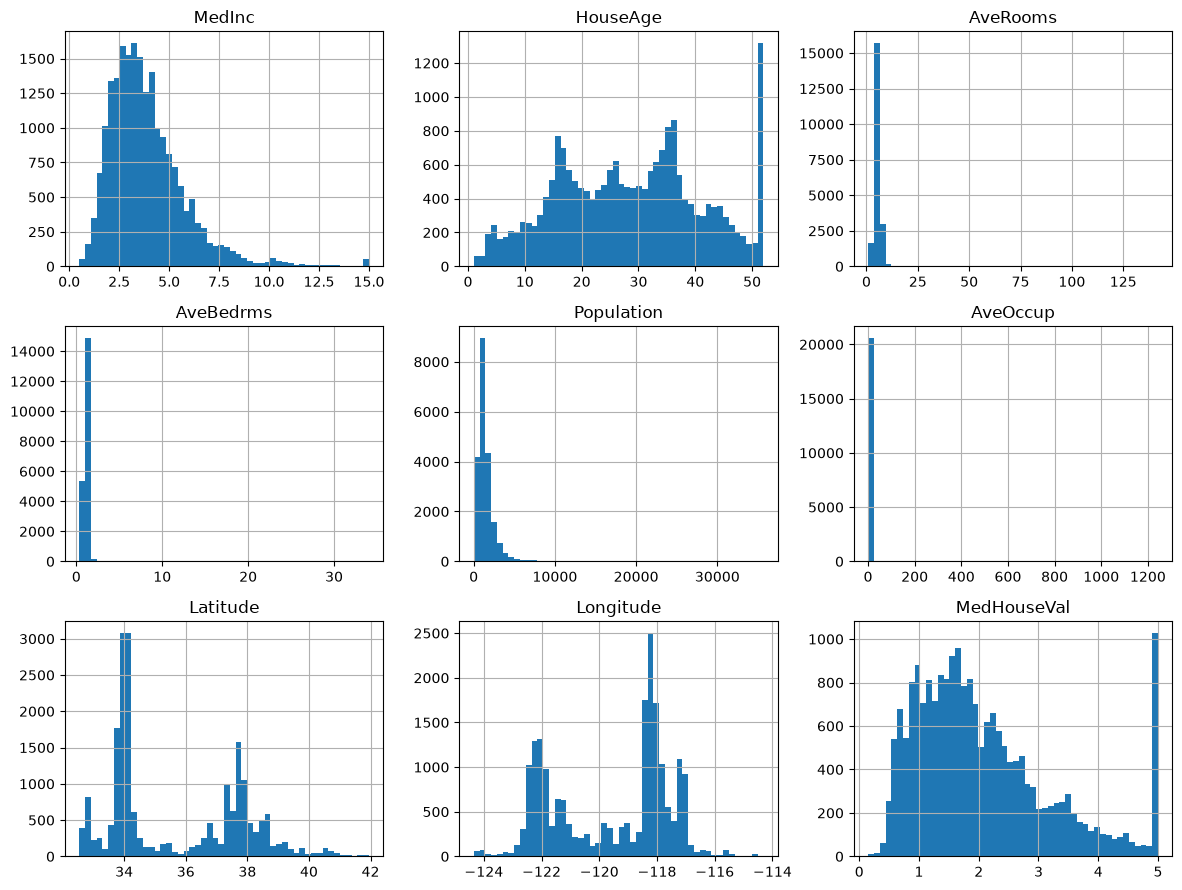

In [9]:
pd.concat([Xc, yc], axis=1).hist(bins=50, figsize=(12, 9))
plt.tight_layout()
plt.show()

- En la variable `HouseAge` hay un pico claro en 52 con un total de 1273 casas: Confirmamos de nuevo que esto es un tope, agrupando las casas de 52 o más años en ese valor. 

- `MedHouseVal` tiene un pico en 15, otro posible tope del que no nos hemos dado cuenta antes. 

- Para `AveRooms`, `AveBedrms` y `AveOccup` el histograma no nos sirve de mucho porque los valores extremos estiran el eje, quedando todo en una única barra. 

- `Population`: Cola larga hacia la derecha, es decir, con más habitantes en el bloque.

- Las coordenadas son bimodales, con dos grupos grandes, que seguramente correspondan a dos zonas muy pobladas. No siguen una distribución normal, lo cual tendremos que tener en cuenta más adelante.

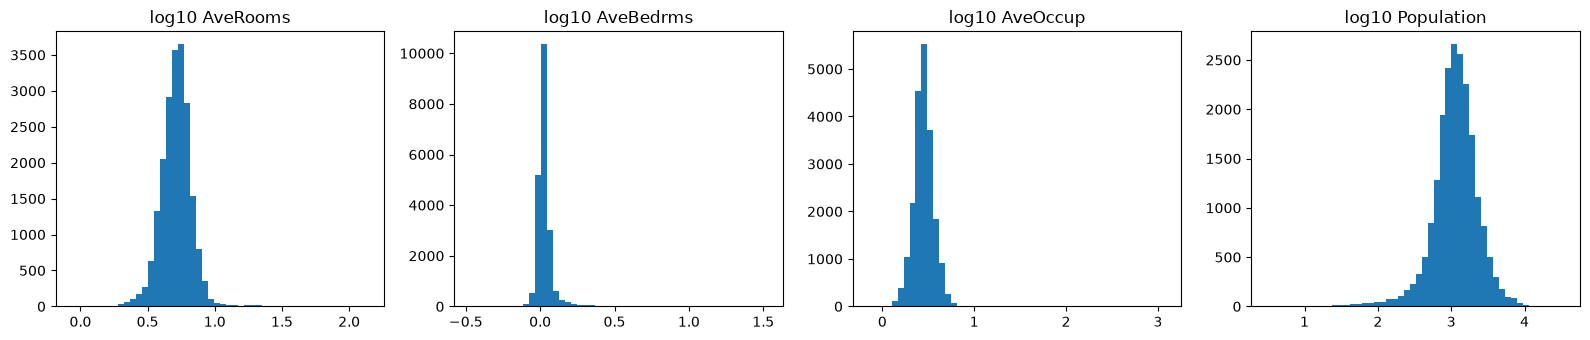

In [13]:
# para ver la forma real de las variables con extremos sin que los valores
# atípicos aplasten la escala
vars_extremas = ["AveRooms", "AveBedrms", "AveOccup", "Population"]
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))
for eje, v in zip(ejes, vars_extremas):
    eje.hist(np.log10(Xc[v]), bins=50)
    eje.set_title("log10 " + v)
plt.tight_layout()
plt.show()

In [14]:
# vemos cuántos hay realmente por encima de un umbral razonable 
for v in vars_extremas: 
    q99 = Xc[v].quantile(0.99)
    print(v, "p99:", round(q99, 2), "| casas por encima:", (Xc[v] > q99).sum(), "| máximo:", round(Xc[v].max(), 2))

AveRooms p99: 10.36 | casas por encima: 207 | máximo: 141.91
AveBedrms p99: 2.13 | casas por encima: 207 | máximo: 34.07
AveOccup p99: 5.39 | casas por encima: 207 | máximo: 1243.33
Population p99: 5805.83 | casas por encima: 207 | máximo: 35682.0


Los histogramas logarítmicos nos permiten ver que las 4 variables pasan a tener una forma de campana bastante simétrica. En el caso de `AveBadrms` es bastante estrecha con una cola hacia la derecha que llega casi hasta 1,5. 

Lo suyo sería aplicar el logaritmo a esas cuatro variables. Es una función fija y no tiene que aprender parámetros, por lo que no habría fuga de la información. El enunciado nos pide comparar el modelo con los datos crudos, pero nosotros también queremos ver qué parte de la mejora es del preprocesado y qué parte la aporta el enjambre.

### 1.4. Correlaciones

Entre la variable objetivo y entre atributos
#### Correlación de las variables para el dataset de California

In [15]:
corr_c  = pd.concat([Xc, yc], axis=1).corr()
print(corr_c["MedHouseVal"].sort_values(ascending=False).round(3))

MedHouseVal    1.000
MedInc         0.688
AveRooms       0.152
HouseAge       0.106
AveOccup      -0.024
Population    -0.025
Longitude     -0.046
AveBedrms     -0.047
Latitude      -0.144
Name: MedHouseVal, dtype: float64


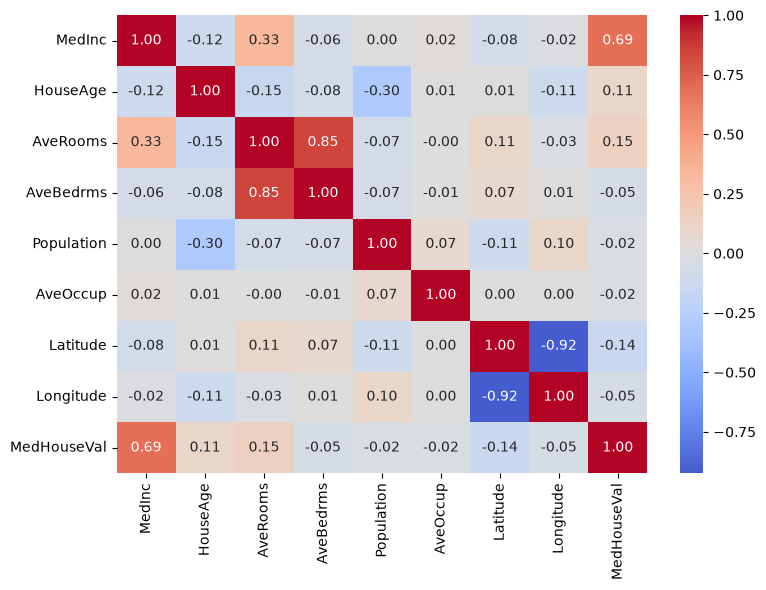

In [16]:
# de manera visual
import seaborn as sns 
plt.figure(figsize=(8, 6))
sns.heatmap(corr_c, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

Vemos que por lo general no hay mucha correlación con la variable objetivo salvo por la variable `MedInc` que obtiene un 0.69. Luego vemos una correlación alta negativa entre la longitud y la latitud, lo cual es esperable dada la naturaleza de las variables. Además, vmos una correlación alta de 0,85 entre `AveRooms` y `AveBedrms` que pueden ser casi redundantes.

#### Correlación de las variables para el dataset de Diabetes

In [17]:
corr_d  = pd.concat([Xd, yd], axis=1).corr()
print(corr_d["target"].sort_values(ascending=False).round(3))

target    1.000
bmi       0.586
s5        0.566
bp        0.441
s4        0.430
s6        0.382
s1        0.212
age       0.188
s2        0.174
sex       0.043
s3       -0.395
Name: target, dtype: float64


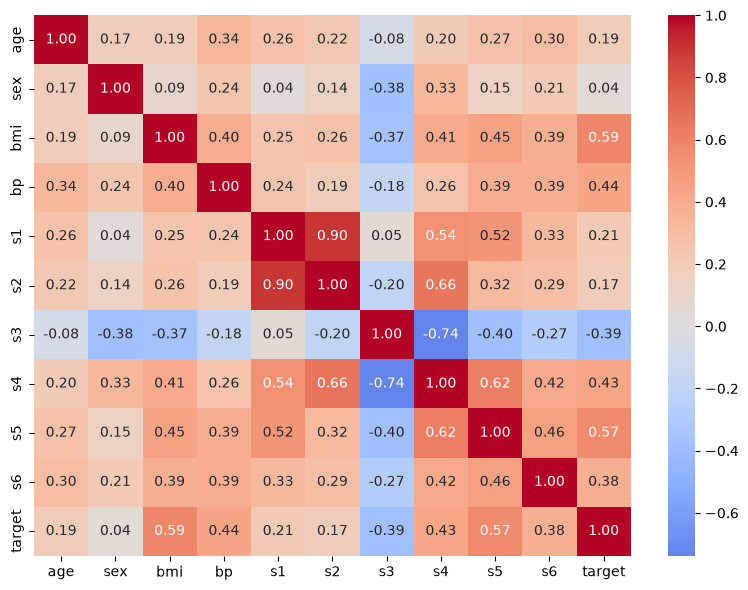

In [18]:
# de manera visual
import seaborn as sns 
plt.figure(figsize=(8, 6))
sns.heatmap(corr_d, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

En general con la variable objetivo no vemos ninguna variable con una correlación demasiado alta, como mucho llegan a 0,59. Entre el resto de variables, la más alta que encontramos es un 0,9 entre la s1 y la s2; así como un -0,74 entre la s3 y s4.

#### Anotación importante

La correlación de Pearson solo mide la relación lineal, y se está calculando con los datos sin transformar. De cara al método que queremos usar, esto es importante ya que si dos atributos están muy correlacionados, en una distancia euclídea, esa dirección cuenta el doble. Esto nos indica que lo mejor sería que los centroides vengan con una métrica aprendida, como pesos por atributo. 

## 2. Partición 
Separamos el entrenamiento y la validación antes de cualquier transformación que aprenda de los datos, como puede ser el escalado. Esto evita la fuga de información. 

In [19]:
from sklearn.model_selection import train_test_split
TEST_SIZE = 0.3
def partir(nombre, seed=SEED): 
    X, y = datos[nombre]
    return train_test_split(X,y, test_size=TEST_SIZE, random_state=seed)

## 3. Líneas base con los datos crudos

El error `e` del modelo M entrenado con $x_t$ sin transformar y evaluado con $X_v$. Todo lo que hacemos se compara luego con esto. 

Nosotros vamos a usar tres familias distintas de modelos de regresión arbitrarios: lineal, basado en distancias (KNN) y árbol. Así podemos ver si la transformación mejora de forma general, o solo para un tipo de modelo. 

Los hiperparámetros del modelo se dejan fijos y sin ajustar. De esta manera se compara de manera justa. 

In [22]:
from sklearn.linear_model   import LinearRegression
from sklearn.neighbors      import KNeighborsRegressor
from sklearn.tree           import DecisionTreeRegressor
from sklearn.metrics        import mean_absolute_error

MODELOS = {
    "Regresión Lineal"      : lambda: LinearRegression(), 
    "KNN"                   : lambda: KNeighborsRegressor(), 
    "Árbol de decisión"     : lambda: DecisionTreeRegressor(random_state=SEED)
}

# para evaluar rápido
def evaluar(Xt, Xv, yt, yv): 
    return {nombre: mean_absolute_error(yv, crear().fit(Xt, yt).predict(Xv))
            for nombre, crear in MODELOS.items()}

In [23]:
for nombre in datos:
    Xt, Xv, yt, yv = partir(nombre)
    print(nombre, {m: round(e, 3) for m, e in evaluar(Xt, Xv, yt, yv).items()})

diabetes {'Regresión Lineal': 43.459, 'KNN': 42.546, 'Árbol de decisión': 59.105}
california {'Regresión Lineal': 0.541, 'KNN': 0.829, 'Árbol de decisión': 0.472}


### Más contexto y línea base preprocesada

Primero: un modelo trivial que nos permita ver de dónde partimos. Un MAE no tiene sentido sin una referencia. Este modelo predice siempre la mediana de train. 

In [24]:
from sklearn.dummy import DummyRegressor
for nombre in datos:
    Xt, Xv, yt, yv = partir(nombre)
    d = DummyRegressor(strategy="median").fit(Xt, yt)
    print(nombre, round(mean_absolute_error(yv, d.predict(Xv)), 3))

diabetes 62.241
california 0.884


Segundo: aplicamos preprocesado ajustado solo con el entrenamiento. Es lo que aplicaremos tras la partición: logaritmo en las cuatro variables de cola larga de Califronia y estandarización. 

In [25]:
from sklearn.preprocessing import StandardScaler
COLS_LOG = {
    "california": ["AveRooms", "AveBedrms", "AveOccup", "Population"],
    "diabetes": [],
}
# método para aplicar el preprocesado
def preprocesar(nombre, Xt, Xv):
    Xt, Xv = Xt.copy(), Xv.copy()
    for c in COLS_LOG[nombre]:
        Xt[c], Xv[c] = np.log(Xt[c]), np.log(Xv[c])
    esc = StandardScaler().fit(Xt)
    return esc.transform(Xt), esc.transform(Xv)

Generamos la línea base preprocesada: 

In [26]:
for nombre in datos:
    Xt, Xv, yt, yv = partir(nombre)
    Xt, Xv = preprocesar(nombre, Xt, Xv)
    print(nombre, {m: round(e, 3) for m, e in evaluar(Xt, Xv, yt, yv).items()})

diabetes {'Regresión Lineal': 43.459, 'KNN': 42.82, 'Árbol de decisión': 58.714}
california {'Regresión Lineal': 0.492, 'KNN': 0.424, 'Árbol de decisión': 0.472}


Hay que tener en cuenta que: 

- El escalador se ajusta solo con el entrenamiento y se aplica a la validación para que no haya fuga de información. 
- Diabetes ya estaba estandarizado, así que el escalado apenas hará nada. Se mantiene para que el proceso sea el mismo en ambos datasets y la comparación sea justa. 
- Esta es la línea base preprocesada que separa lo que aporta el mismo frente a solo el algoritmo genético. 

## 4. Repetición con varias semillas

Para poder sacar conclusiones correctas, repetimos con 10 particiones y derivamos la media y la desviación. 

In [27]:
SEEDS = [SEED + i for i in range(10)]

def repetir(nombre, preproc):
    filas = []
    for s in SEEDS:
        Xt, Xv, yt, yv = partir(nombre, seed=s)
        if preproc:
            Xt, Xv = preprocesar(nombre, Xt, Xv)
        filas.append(evaluar(Xt, Xv, yt, yv))
    return pd.DataFrame(filas)

In [28]:
for nombre in datos:
    for preproc in (False, True):
        r = repetir(nombre, preproc)
        print(nombre, "preprocesado" if preproc else "crudo")
        print(r.agg(["mean", "std"]).round(3))
        print()

diabetes crudo
      Regresión Lineal     KNN  Árbol de decisión
mean            45.372  47.814             61.616
std              2.114   3.250              4.229

diabetes preprocesado
      Regresión Lineal     KNN  Árbol de decisión
mean            45.372  48.081             61.621
std              2.114   3.093              4.214

california crudo
      Regresión Lineal    KNN  Árbol de decisión
mean             0.532  0.826              0.466
std              0.006  0.010              0.012

california preprocesado
      Regresión Lineal    KNN  Árbol de decisión
mean             0.484  0.413              0.465
std              0.004  0.005              0.012



### Análisis Diabetes
El preprocesado apenas cambia nada aquí. Justo con la semilla de 13 parece ser optimista, pero en media la regresión lineal lo hace mejor que la KNN (con la semilla de 13 era lo contrario). Esto nos demuestra que es importante hacer maś de una partición. 
### Análisis California 
Sí que cambia con el preprocesado, obteniendo de base el KNN con un 0.413. 
### Apunte para más adelante
La desviación mide cuánto varía el resultado entre particiones. Las particiones, al poder solaparse, no son del todo independientes. Por ello, al comparar métodos, usaremos un test de emparejado como el de Wilcoxon sobre las mismas particiones.

## 5. Control con polinómicas de grado 2

Primero vamos a usar un control con polinómicas de grado 2, para poder comprobar si una transformación simple y sin optimizar puede igualar al enjambre que queremos desarrollar más adelante.

In [29]:
# modificamos el repetir para que pueda aceptar cualquier transformación 
def repetir(nombre, transformar=None):
    filas = []
    for s in SEEDS:
        Xt, Xv, yt, yv = partir(nombre, seed=s)
        if transformar:
            Xt, Xv = transformar(nombre, Xt, Xv)
        filas.append(evaluar(Xt, Xv, yt, yv))
    return pd.DataFrame(filas)

In [30]:
# añadimos la transformación polinómica
from sklearn.preprocessing import PolynomialFeatures

def preproc_poly(nombre, Xt, Xv):
    Xt, Xv = preprocesar(nombre, Xt, Xv)
    p = PolynomialFeatures(2, include_bias=False).fit(Xt)
    return p.transform(Xt), p.transform(Xv)

In [31]:
# ejecutamos en los dos datasets
for nombre in datos:
    r = repetir(nombre, preproc_poly)
    print(nombre, "polinómico grado 2")
    print(r.agg(["mean", "std"]).round(3))
    print()

diabetes polinómico grado 2
      Regresión Lineal     KNN  Árbol de decisión
mean            50.820  49.254             65.056
std              3.661   3.615              2.774

california polinómico grado 2
      Regresión Lineal    KNN  Árbol de decisión
mean             0.428  0.412              0.466
std              0.005  0.005              0.009



### Análisis Diabetes
En este caso el control polinómico de grado 2 empeora. Esto puede deberse a que el paso de 10 a 65 atributos con tan pocas filas provoca sobreajuste a los datos. En la regresión lineal la diferencia supera la desviación entre semillas (5,4 vs 3,7). En los otros dos no está tan claro. 
### Análisis California
Solo parece mejorar a la regresión lineal, pero no al resto de los modelos. La regresión ineal mejora un 12%, mientras los otros dos apenas cambian. 

### Significancia 
Dejamos aquí la tabla de objetivos: recogen las medias +- desviación de las 10 particiones con lso valores de nuestras salidas. La última columna es la mejor media entre las tres líneas base.

| Dataset | Modelo | Crudo | Preprocesado | Polinómico (grado 2) | Objetivo a superar |
|---|---|---|---|---|---|
| Diabetes | Regresión lineal | 45.372 ± 2.114 | 45.372 ± 2.114 | 50.820 ± 3.661 | **45.372** |
| Diabetes | KNN | 47.814 ± 3.250 | 48.081 ± 3.093 | 49.254 ± 3.615 | **47.814** |
| Diabetes | Árbol de decisión | 61.616 ± 4.229 | 61.621 ± 4.214 | 65.056 ± 2.774 | **61.616** |
| California | Regresión lineal | 0.532 ± 0.006 | 0.484 ± 0.004 | 0.428 ± 0.005 | **0.428** |
| California | KNN | 0.826 ± 0.010 | 0.413 ± 0.005 | 0.412 ± 0.005 | **0.412** |
| California | Árbol de decisión | 0.466 ± 0.012 | 0.465 ± 0.012 | 0.466 ± 0.009 | **0.465** |


## 6. Centroides sin optimizar
Definición de la transformación del método con centroides fijos: las distancias a k centroides, concatenadas con los atributos. Aquí tenemos dos controles: 

- Centroides por bins de `y` - la idea inicial sin uso de enjambre
- Centroides aleatorios - si igualan a los anteriores, entonces el centroide no aporta información.

Primero debemos cambiar dos funciones que ya tenemos para que las transformaciones reciban el `yt`: 

In [34]:
# funciones de apoyo
# calculo de la distancia entre el punto y el centroide
# distancia euclidea
def distancias(X, C):
    return np.sqrt(((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))

# bins para los centroides
def centroides_bins(X, y, k):
    cortes = np.quantile(y, np.linspace(0, 1, k + 1)[1:-1])
    clase = np.digitize(y, cortes)
    return np.array([X[clase == i].mean(axis=0) for i in range(k)])

In [35]:
K = 5

def preproc_bins(nombre, Xt, Xv, yt=None):
    Xt, Xv = preprocesar(nombre, Xt, Xv)
    C = centroides_bins(Xt, np.asarray(yt), K)
    return np.c_[Xt, distancias(Xt, C)], np.c_[Xv, distancias(Xv, C)]

def preproc_aleatorios(nombre, Xt, Xv, yt=None):
    Xt, Xv = preprocesar(nombre, Xt, Xv)
    C = np.random.default_rng(SEED).normal(size=(K, Xt.shape[1]))
    return np.c_[Xt, distancias(Xt, C)], np.c_[Xv, distancias(Xv, C)]

In [38]:
def repetir_con_y(nombre, transformar):
    filas = []
    for s in SEEDS:
        Xt, Xv, yt, yv = partir(nombre, seed=s)
        Xt, Xv = transformar(nombre, Xt, Xv, yt)
        filas.append(evaluar(Xt, Xv, yt, yv))
    return pd.DataFrame(filas)

In [39]:
for nombre in datos:
    for etiqueta, f in [("centroides por bins", preproc_bins),
                        ("centroides aleatorios", preproc_aleatorios)]:
        r = repetir_con_y(nombre, f)
        print(nombre, etiqueta)
        print(r.agg(["mean", "std"]).round(3))
        print()

diabetes centroides por bins
      Regresión Lineal     KNN  Árbol de decisión
mean            44.337  46.860             62.371
std              2.257   2.744              4.028

diabetes centroides aleatorios
      Regresión Lineal     KNN  Árbol de decisión
mean            44.779  48.035             61.833
std              2.134   3.194              2.386

california centroides por bins
      Regresión Lineal    KNN  Árbol de decisión
mean             0.467  0.417              0.469
std              0.004  0.004              0.010

california centroides aleatorios
      Regresión Lineal    KNN  Árbol de decisión
mean             0.478  0.418              0.475
std              0.003  0.005              0.009



### Comparación con el objetivo

- En el caso de California los centroides fijos no superan ningún objetivo. La regresión lineal mejora respecto a la preprocesada, pero la polinómica sigue por delante. KNN y árbol quedan igual o ligeramente peor. 

- En Diabetes los centroides por bins superan el objetivo con regresión lineal y KNN, por algo menos de un punto. Esa diferencia es menor que la desviación entre particiones, por lo que no podemos tenerla como concluyente.

### Conclusiones

Esto es en parte lo que esperábamos de un control, un conjunto de centroides sin optimizar no es suficiente. El enjambre debe encontrar posiciones que mejoren de verdad lo anterior. 

## 7. Preparación del enjambre